In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
PROJECT = os.path.expanduser("~/spline_flows")
FIG = os.path.join(PROJECT, "figures")
os.makedirs(FIG, exist_ok=True)
print("working in:", os.getcwd())

working in: /home/eychung/spline_flows


In [2]:
import glob, os
import numpy as np, pandas as pd

DATA = os.path.expanduser("~/data/LAFAN1_g1/g1")
FPS = 30

clips = {}
for f in sorted(glob.glob(f"{DATA}/walk*.csv")):
    name = os.path.basename(f)[:-4]
    clips[name] = pd.read_csv(f, header=None).to_numpy()
    print(f"{name:18s} {clips[name].shape} ~{len(clips[name]) / FPS:.0f} s")
print("total frames:", sum(len(c) for c in clips.values()))

walk1_subject1     (7840, 36) ~261 s
walk1_subject2     (7840, 36) ~261 s
walk1_subject5     (7840, 36) ~261 s
walk2_subject1     (7146, 36) ~238 s
walk2_subject3     (7146, 36) ~238 s
walk2_subject4     (7146, 36) ~238 s
walk3_subject1     (7399, 36) ~247 s
walk3_subject2     (7399, 36) ~247 s
walk3_subject3     (7399, 36) ~247 s
walk3_subject4     (7399, 36) ~247 s
walk3_subject5     (7399, 36) ~247 s
walk4_subject1     (4918, 36) ~164 s
total frames: 86871


In [3]:
a, b = clips["walk1_subject1"][:, 7:], clips["walk1_subject2"][:, 7:]
print(np.abs(a - b).max())

2.273459


In [4]:
TEST_FILES = ["walk1_subject2", "walk3_subject2"]

In [5]:
c = clips["walk1_subject1"]
xy = c[:, 0:2]
per_frame = np.linalg.norm(np.diff(xy, axis=0), axis=1)
speed = per_frame * FPS
print("median speed (m/2):", round(np.median(speed), 2))

median speed (m/2): 0.43


In [6]:
t = np.arange(len(speed)) / FPS # secs

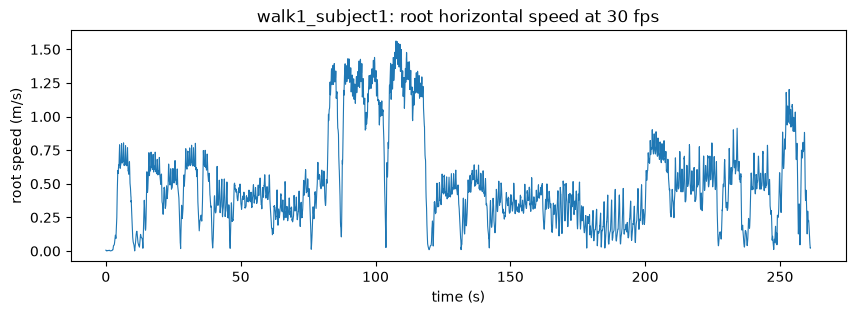

In [7]:
plt.figure(figsize=(10, 3))
plt.plot(t, speed, linewidth=0.8)
plt.xlabel("time (s)")
plt.ylabel("root speed (m/s)")
plt.title("walk1_subject1: root horizontal speed at 30 fps")
plt.savefig("walk_horizontal_speed.png", dpi=300, bbox_inches="tight")
plt.show()

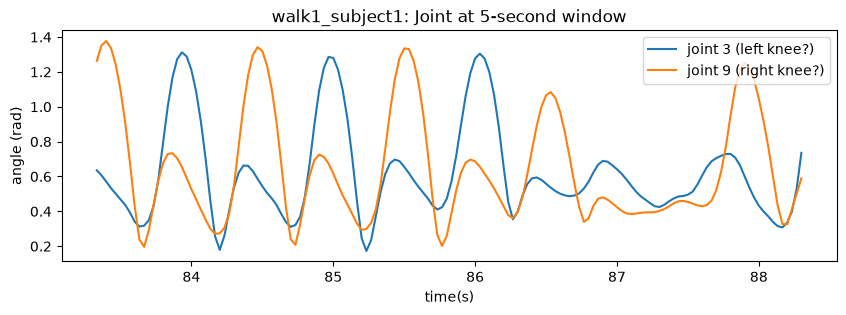

In [8]:
J = c[:, 7:]
t = np.arange(2500, 2650) / FPS
window = slice(2500, 2650)
Jw = J[window, :]
plt.figure(figsize=(10,3))
plt.plot(t, Jw[:, 3], label="joint 3 (left knee?)")
plt.plot(t, Jw[:, 9], label="joint 9 (right knee?)")
plt.xlabel("time(s)")
plt.ylabel("angle (rad)")
plt.title("walk1_subject1: Joint at 5-second window")
plt.legend()
plt.savefig("figures/knees.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
plt.savefig("knees.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [10]:
print(os.getcwd())

/home/eychung/spline_flows


In [11]:
%pip install mujoco

Note: you may need to restart the kernel to use updated packages.


In [12]:
import mujoco
m = mujoco.MjModel.from_xml_path(os.path.expanduser("~/mujoco_menagerie/unitree_g1/g1.xml"))
print("joints in model:", m.njnt) # should be 30, 29 motor joints and root joint
names = [m.joint(i).name for i in range(1, m.njnt)]
lo, hi = m.jnt_range[1:, 0], m.jnt_range[1:, 1]
allJ = np.concatenate([c[:, 7:] for c in clips.values()])
for i, n in enumerate(names):
    dmin, dmax = allJ[:, i].min(), allJ[:, i].max()
    ok = dmin >= lo[i] - 0.05 and dmax <= hi[i] + 0.05
    print(f"{i:2d} {n:28s} data [{dmin:+.2f}, {dmax:+.2f}] "
        f"limit [{lo[i]:+.2f}, {hi[i]:+.2f}]{'' if ok else ' <-- OUTSIDE'}")

joints in model: 30
 0 left_hip_pitch_joint         data [-2.10, +0.75] limit [-2.53, +2.88]
 1 left_hip_roll_joint          data [-0.51, +0.98] limit [-0.52, +2.97]
 2 left_hip_yaw_joint           data [-1.04, +2.12] limit [-2.76, +2.76]
 3 left_knee_joint              data [+0.08, +2.87] limit [-0.09, +2.88]
 4 left_ankle_pitch_joint       data [-0.86, +0.51] limit [-0.87, +0.52]
 5 left_ankle_roll_joint        data [-0.26, +0.26] limit [-0.26, +0.26]
 6 right_hip_pitch_joint        data [-2.03, +0.63] limit [-2.53, +2.88]
 7 right_hip_roll_joint         data [-1.26, +0.51] limit [-2.97, +0.52]
 8 right_hip_yaw_joint          data [-1.77, +1.25] limit [-2.76, +2.76]
 9 right_knee_joint             data [+0.08, +2.87] limit [-0.09, +2.88]
10 right_ankle_pitch_joint      data [-0.87, +0.51] limit [-0.87, +0.52]
11 right_ankle_roll_joint       data [-0.26, +0.26] limit [-0.26, +0.26]
12 waist_yaw_joint              data [-0.36, +0.57] limit [-2.62, +2.62]
13 waist_roll_joint            

In [13]:
TRAIN_FILES = [name for name in clips if name not in TEST_FILES]

In [14]:
def make_windows(file_list):
    train_history = []
    train_future = []
    history = 8
    horizon = 32
    stride = 4
    for file in file_list:
        J = clips[file][:, 7:]
        for s in range(0, len(J) - (history + horizon) + 1, stride):
            train_history.append(J[s:s + history])
            train_future.append(J[s + history:s + history + horizon])
    X_train = np.stack(train_history)
    Y_train = np.stack(train_future)
    print(X_train.shape, Y_train.shape)
    return X_train, Y_train

In [15]:
X_train, Y_train = make_windows(TRAIN_FILES)

(17813, 8, 29) (17813, 32, 29)


In [16]:
X_test, Y_test = make_windows(TEST_FILES)

(3791, 8, 29) (3791, 32, 29)


In [17]:
print(J)

[[-0.119781  0.045812  0.051567 ...  0.098212  0.173991 -0.29095 ]
 [-0.125687  0.050716  0.052802 ...  0.132666  0.213831 -0.327679]
 [-0.130957  0.053144  0.052262 ...  0.154509  0.239329 -0.340656]
 ...
 [-0.128608 -0.024015 -0.005581 ... -0.810851  0.380826 -0.026881]
 [-0.130834 -0.023779 -0.006351 ... -0.804111  0.38857  -0.02521 ]
 [-0.131161 -0.023547 -0.007652 ... -0.800266  0.39606  -0.032042]]


In [18]:
all_training_J = np.concatenate([clips[file][:, 7:] for file in TRAIN_FILES])
print(all_training_J.shape)
J_min = all_training_J.min(axis=0)
J_max = all_training_J.max(axis=0)
print(J_min.shape, J_max.shape)

    

(71632, 29)
(29,) (29,)


In [19]:
np.savez(
    "walk_windows_history8_horizon32_stride4.npz",
    X_train=X_train, Y_train=Y_train,
    X_test=X_test, Y_test=Y_test,
    J_min=J_min, J_max=J_max,
    train_files=np.array(TRAIN_FILES), test_files=np.array(TEST_FILES),
)

In [20]:
d = np.load("walk_windows_history8_horizon32_stride4.npz")
for k in d.files:
    print(k, d[k].shape)

X_train (17813, 8, 29)
Y_train (17813, 32, 29)
X_test (3791, 8, 29)
Y_test (3791, 32, 29)
J_min (29,)
J_max (29,)
train_files (10,)
test_files (2,)


In [21]:
import os; print(os.getcwd())

/home/eychung/spline_flows
